# 04. Outlier Detection and Handling

**Before this notebook:** read `notes/04_outliers.md`.

**Goal:** check whether the numeric features contain extreme values, and practise the handling options.

**Steps**
1. Load the cleaned data
2. Practice on a tiny example
3. Write a reusable IQR function
4. Check the real numeric columns
5. Cross-check with z-scores and a box plot
6. Practice handling on a *copy* with injected errors
7. Summary and decision
8. Exercise

## Step 1: Load the cleaned data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../../reports/figures")

df = pd.read_csv("../../data/processed/telco_clean.csv")
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

We only check `tenure`, `MonthlyCharges` and `TotalCharges`. `SeniorCitizen` is stored as 0/1 but it is really a category, so outliers make no sense for it.

## Step 2: Practice on a tiny example

The 9-customer example from the notes. Eight normal spends and one suspicious 900.

In [2]:
spend = pd.Series([20, 25, 22, 30, 28, 26, 24, 27, 900])

q1 = spend.quantile(0.25)
q3 = spend.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print(f"Q1={q1}, Q3={q3}, IQR={iqr}")
print(f"Fences: lower={lower}, upper={upper}")
print("Outliers:", spend[(spend < lower) | (spend > upper)].tolist())
print()
print("Mean with the outlier:   ", round(spend.mean(), 1))
print("Mean without the outlier:", round(spend[spend <= upper].mean(), 1))
print("Median with the outlier: ", spend.median())

Q1=24.0, Q3=28.0, IQR=4.0
Fences: lower=18.0, upper=34.0
Outliers: [900]

Mean with the outlier:    122.4
Mean without the outlier: 25.2
Median with the outlier:  26.0


**Line by line**
- `quantile(0.25)`: the value 25% of the way through the sorted data (Q1). `0.75` gives Q3.
- `iqr = q3 - q1`: the spread of the middle 50% of the data.
- `lower`/`upper`: the fences, 1.5 IQRs beyond the quartiles. The factor 1.5 is a widely used convention, not a law.
- `(spend < lower) | (spend > upper)`: True for values outside the fences. `|` means "or". The brackets are required.
- `spend[mask]`: keeps the values where the mask is True.

**How to read the output**
- Fences are 18 and 34, so **900 is flagged**.
- One outlier moves the mean from about 25 to about 122. The **median** barely moves (26). This is exactly why the median is called *robust*.

## Step 3: A reusable function

We will check three columns, so we put the logic into a function. *Input:* a Series. *Output:* the fences and a True/False mask of outliers.

In [3]:
def iqr_outliers(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - factor * iqr, q3 + factor * iqr
    mask = (series < lower) | (series > upper)
    return lower, upper, mask

# Test on the toy example: should find the 900.
print(iqr_outliers(spend)[2].sum(), "outlier(s) found in toy data")

1 outlier(s) found in toy data


Testing a function on a case where you already know the answer is a good habit. Here we know there is exactly one outlier.

## Step 4: Check the real numeric columns

In [4]:
rows = []
for col in num_cols:
    lower, upper, mask = iqr_outliers(df[col])
    rows.append({
        "column": col,
        "min": df[col].min(),
        "max": df[col].max(),
        "lower_fence": round(lower, 1),
        "upper_fence": round(upper, 1),
        "n_outliers": int(mask.sum()),
    })

pd.DataFrame(rows)

,column,min,max,lower_fence,upper_fence,n_outliers
0,tenure,0.00,72.00,-60.0,124.0,0
1,MonthlyCharges,18.25,118.75,-46.0,171.4,0
2,TotalCharges,0.00,8684.80,-4683.5,8868.7,0


**Line by line**
- We loop over the three columns, call our function, and collect the results as small dictionaries in a list.
- `pd.DataFrame(rows)`: turns a list of dictionaries into a table, one row per dictionary.

**How to read the output**
- Every column has **0 outliers**. Every minimum and maximum sits inside its fences. For example, `MonthlyCharges` runs from $18 to $119 and the upper fence is about $171.
- **This is a legitimate finding.** `tenure` can only be between 0 and 72 months in this data, and prices come from a plan menu, so wild values are unlikely.
- `TotalCharges` is skewed (notebook 03), but skewed is not the same as having outliers. Its long tail is real: long-time customers on expensive plans have paid a lot.

## Step 5: Cross-check with z-scores and a box plot

Two independent methods that agree give more confidence.

Values with |z| > 3:
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


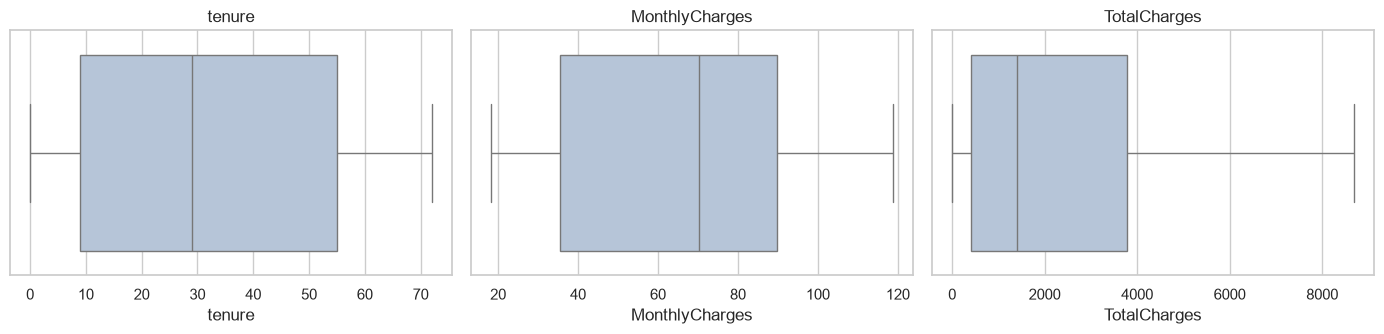

In [5]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
print("Values with |z| > 3:")
print((z.abs() > 3).sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_boxplots_outlier_check.png", dpi=120)
plt.show()

**Line by line**
- `(df[num_cols] - df[num_cols].mean()) / df[num_cols].std()`: the z-score formula applied to all three columns at once. Pandas does it column by column.
- `z.abs() > 3`: True where the value is more than 3 standard deviations from the mean. `.sum()` counts them per column.
- `sns.boxplot(x=...)`: a horizontal box plot. Any dot beyond the whiskers is an IQR outlier.

**How to read the output**
- The z-score count is **0** for all three columns.
- The box plots have **no dots** outside the whiskers.
- Both methods agree: **there are no outliers to treat.** So we keep the data as it is.

## Step 6: Practise handling on a *copy* with injected errors

Since our data is clean, we create a **damaged copy** to practise the handling options. Imagine a data-entry error where some `MonthlyCharges` got an extra zero. The real `df` stays untouched.

In [6]:
rng = np.random.default_rng(42)                   # fixed seed: same result every run
dirty = df.copy()                                 # a separate copy, so df is not changed

bad_idx = rng.choice(dirty.index, size=10, replace=False)   # pick 10 random rows
dirty.loc[bad_idx, "MonthlyCharges"] *= 10                  # simulate the 'extra zero' typo

lower, upper, mask = iqr_outliers(dirty["MonthlyCharges"])
print(f"Upper fence: {upper:.1f}")
print("Outliers detected:", mask.sum())
print("Max value:", dirty["MonthlyCharges"].max())

Upper fence: 171.5
Outliers detected: 10
Max value: 1077.5


**Line by line**
- `np.random.default_rng(42)`: a random number generator with a fixed seed. **Reproducibility**: the same 10 rows are picked every time.
- `df.copy()`: makes an independent copy. Without `.copy()`, changing `dirty` could also change `df`.
- `rng.choice(..., replace=False)`: picks 10 different row labels.
- `dirty.loc[rows, col] *= 10`: multiplies those cells by 10.

**Expected output:** about 10 outliers found, with a maximum over $1,000, far above the upper fence of about $171. Our detector works.

Now the three handling options side by side:

In [7]:
col = "MonthlyCharges"
lower, upper, mask = iqr_outliers(dirty[col])

# Option 1: remove the rows
removed = dirty[~mask]                            # ~ means NOT

# Option 2: cap (clip) values to the fences
capped = dirty[col].clip(lower=lower, upper=upper)

# Option 3: log transform (squashes large values)
logged = np.log1p(dirty[col])                     # log(1 + x), safe for 0

summary = pd.DataFrame({
    "original_clean":   df[col].describe(),
    "dirty":            dirty[col].describe(),
    "after_removing":   removed[col].describe(),
    "after_capping":    capped.describe(),
}).round(1).loc[["count", "mean", "std", "max"]]
summary

,original_clean,dirty,after_removing,after_capping
count,7043.0,7043.0,7033.0,7043.0
mean,64.8,65.8,64.7,64.9
std,30.1,41.9,30.1,30.3
max,118.8,1077.5,118.8,171.5


**Line by line**
- `dirty[~mask]`: `~` flips True/False, so we keep only the rows that are **not** outliers. The table shrinks.
- `.clip(lower, upper)`: values below `lower` become `lower`, values above `upper` become `upper`. Every row stays.
- `np.log1p(x)`: computes `log(1 + x)`. It shrinks large numbers a lot and small numbers a little.
- `.describe()` for each version, then `.loc[[...]]` picks four useful rows to compare.

**How to read the output**
- **dirty:** only 10 rows changed, yet the standard deviation jumped from about 30 to about 42, the mean moved up, and the max is over $1,000. The typo damaged the statistics. (Many models rely on the spread, not just the average.)
- **after_removing:** the numbers return close to the original, but `count` dropped by about 10 rows.
- **after_capping:** the numbers are also close to the original, with **all rows kept**. The capped values sit at the fence ($171), not at their true value, but that is near enough for modelling.

**Which to choose?**
- Obvious typo, very few rows → **remove** (or better, fix, if the true value is known).
- Real extreme values you want to keep but limit → **cap**.
- A long, smooth right tail (like `TotalCharges`) with no errors → consider a **log transform** (affects the shape of the whole column, not just a few values).

Let's see what the log transform does to the *real*, skewed `TotalCharges`:

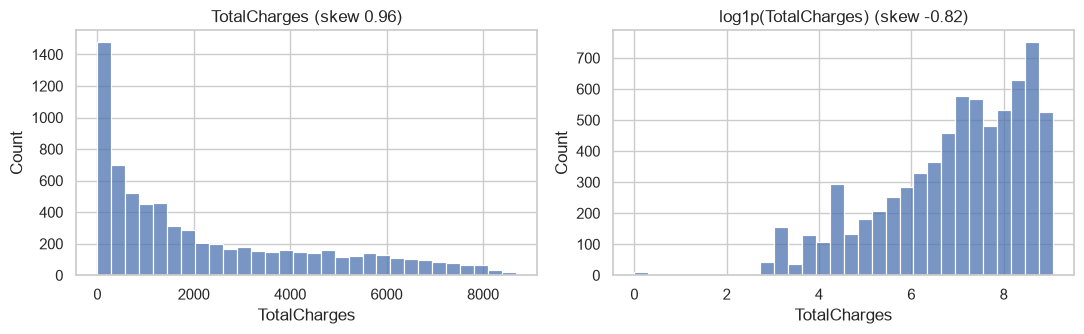

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["TotalCharges"], bins=30, ax=axes[0])
axes[0].set_title(f"TotalCharges (skew {df['TotalCharges'].skew():.2f})")
sns.histplot(np.log1p(df["TotalCharges"]), bins=30, ax=axes[1])
axes[1].set_title(f"log1p(TotalCharges) (skew {np.log1p(df['TotalCharges']).skew():.2f})")
plt.tight_layout()
plt.show()

**How to read the output:** the log makes the long right tail shorter, but it flips the problem: the many customers with very small totals (about 800 have paid under $100) now form a long tail on the *left*, and the skew becomes negative (about -0.82 instead of +0.96). So the log is not an automatic improvement here. We **do not** apply it, because (1) there are no real outliers, and (2) our main models (trees, forests) don't need it. In notebook 06 we will apply *scaling*, which is enough for the models that are sensitive to feature size.

**Lesson:** do not transform data just because a tool exists. Transform when there is a reason.

## Step 7: Summary and decision

| Check | Result |
|---|---|
| IQR rule on `tenure`, `MonthlyCharges`, `TotalCharges` | 0 outliers |
| z-score > 3 | 0 values |
| Box plots | No points beyond the whiskers |
| **Decision** | **No outlier removal or capping.** The data is unchanged. |

We practised removing, capping and transforming on a damaged copy so that you know how to do it on future datasets.

**Next:** `05_train_test_split`: split the data into training and test sets, and learn why preprocessing must be fitted on the training set only.

---
## Exercise

1. Change the injected error so only **3** rows get multiplied by 10. Do the IQR rule and the z-score rule both still detect them? (Hint: with few outliers, the z-score may still work, but try 1 row too.)
2. Use `iqr_outliers(df["tenure"], factor=0.5)` (a much stricter rule). How many rows does it flag? Why is a bigger factor usually safer?
3. **Think:** you are told to build a Decision Tree model and a KNN model on a dataset with real, rare, extreme values. Which model would be more affected? Which handling option would you pick, and why?

In [9]:
# Exercise 1

In [10]:
# Exercise 2